# Exercise 11 — Support Vector Machine (SVM)

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Perform SVM classification using Linear, Polynomial, RBF and Sigmoid kernels and compare their performance.

## Dataset
Expected path: `heart_disease_dataset.csv`. Obtain the dataset from an authorised source and place it at the expected path. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Load data and separate the Heart Disease target.
2. Identify numeric and categorical features.
3. Scale numeric features and one-hot encode categorical features.
4. Split 80:20 with stratification.
5. Train SVM models with all four kernels.
6. Calculate accuracy, precision, recall and F1 for each.
7. Compare results in a table and bar plot.

## Implementation
The following code is copied from the existing `ex-11.py` program and split into notebook cells for interactive execution. The original Python program is unchanged.

Run cells from top to bottom. Outputs and charts are generated when executed with the dataset and required libraries available.

Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

/tmp/ipykernel_2832/405041756.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns



SVM Kernel: sigmoid
Accuracy : 0.825
Precision: 0.8028169014084507
Recall   : 0.7307692307692307
F1 Score : 0.7651006711409396

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       122
           1       0.80      0.73      0.77        78

    accuracy                           0.82       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.82      0.82       200



Kernel Comparison:
    Kernel  Accuracy  Precision    Recall  F1 Score
0   linear     0.875   0.873239  0.794872  0.832215
1     poly     0.925   0.931507  0.871795  0.900662
2      rbf     0.905   0.893333  0.858974  0.875817
3  sigmoid     0.825   0.802817  0.730769  0.765101


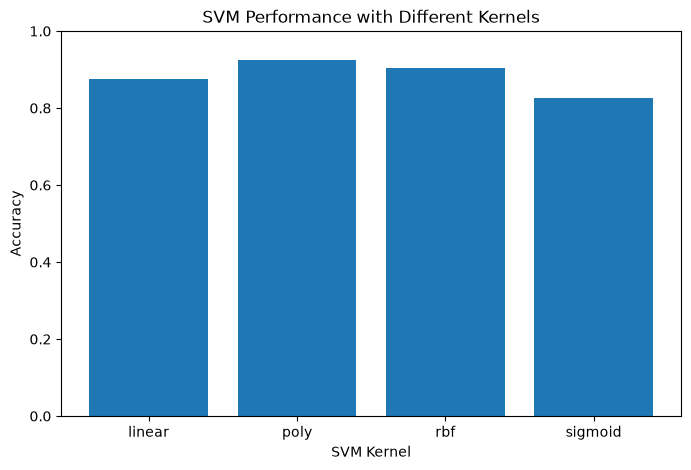


Result:
SVM classification was successfully performed
using Linear, Polynomial, RBF and Sigmoid kernels.


In [1]:
# EXERCISE – 11 (SUPPORT VECTOR MACHINE)

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("\nNumerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

kernels = ["linear", "poly", "rbf", "sigmoid"]

results = []

for kernel in kernels:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("svm", SVC(kernel=kernel, random_state=42))
        ]
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append([
        kernel,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n======================================")
    print("SVM Kernel:", kernel)
    print("======================================")

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(
    results,
    columns=[
        "Kernel",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n\nKernel Comparison:")
print(results_df)

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy"]
)

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("SVM Performance with Different Kernels")
plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

print("\nResult:")
print("SVM classification was successfully performed")
print("using Linear, Polynomial, RBF and Sigmoid kernels.")


## Result summary from the practical record
The polynomial kernel performed best with accuracy 0.925 and F1 0.9007, followed by RBF (accuracy 0.905), linear (0.875) and sigmoid (0.825).

This summary is transcribed from the supplied Word record; it is not a fresh notebook execution. Run the cells to produce current outputs.

## Conclusion
Summarise findings from your execution and note limitations.

## Reproducibility
Record your Python version, dataset source/version and installed dependency versions.